# Práctica 2: Análisis Exploratorio de Datos (EDA) y Preparación de Datasets

## 1. Comprensión del dominio del dataset

### Dataset 1: Titanic
**Variable objetivo:** Supervivencia
* **¿Qué representa cada fila?** Representa a un pasajero individual que viajaba a bordo del Titanic (incluye sus características como edad, sexo, tarifa pagada y clase en la que viajaba).
* **¿La variable objetivo estaría disponible en un escenario real?** No antes del suceso. La supervivencia se conoce solo después de que ocurre el desastre.
* **¿Existen identificadores o variables con fuga de información?** Sí. El `PassengerId`, `Name` y `Ticket` son identificadores que no aportan valor predictivo y deben descartarse.
* **¿Qué decisiones podrían afectar de forma desigual a distintos grupos?** El modelo aprenderá sesgos históricos ("mujeres y niños primero", prioridad a la Primera Clase). Usar esto hoy crearía un modelo que discrimina por género o estatus socioeconómico.

### Dataset 2: Telco Customer Churn
**Variable objetivo:** Abandono 
* **¿Qué representa cada fila?** Representa a un cliente individual de la empresa de telecomunicaciones y los servicios que tiene contratados.
* **¿La variable objetivo estaría disponible en un escenario real?** Sí y no. Tenemos el dato histórico de quién canceló, pero para predecir el futuro, esta variable es justo la que no tenemos y queremos adivinar.
* **¿Existen identificadores o variables con fuga de información?** Sí, el `customerID` es un identificador único que debe eliminarse. 
* **¿Qué decisiones podrían afectar de forma desigual a distintos grupos?** Variables como `SeniorCitizen` (Tercera edad) o el género podrían sesgar al modelo para clasificar injustamente a ciertos grupos demográficos como "clientes riesgosos".

### Prueba de Carga de Datasets


In [11]:
import pandas as pd

# Cargar datos usando rutas relativas
df_titanic = pd.read_csv('../data/raw/titanic.csv')
df_telco = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')

print(f"Titanic cargado: {df_titanic.shape[0]} filas.")
print(f"Telco cargado: {df_telco.shape[0]} filas.")

Titanic cargado: 891 filas.
Telco cargado: 7043 filas.


## 2. Data Profiling

En esta sección realizaremos un perfilado de los datos para diagnosticar su calidad, identificando tipos de variables, porcentajes de valores nulos, valores únicos y estadísticas descriptivas básicas.

### Función que genera un reporte de Data Profiling.
Calcula nulos, valores únicos y tipos de datos.

In [12]:
def hacer_profiling(df):
    # 1. Información básica
    profiling = pd.DataFrame(df.dtypes, columns=['Tipo_de_Dato'])
    
    # 2. Conteo y porcentaje de valores nulos (ausentes)
    profiling['Valores_Nulos'] = df.isnull().sum()
    profiling['Porcentaje_Nulos_%'] = round((df.isnull().sum() / len(df)) * 100, 2)
    
    # 3. Cantidad de valores únicos
    profiling['Valores_Unicos'] = df.nunique()

    profiling = profiling.reset_index()
    profiling = profiling.rename(columns={'index': 'Columna'})
    
    return profiling.sort_values(by='Porcentaje_Nulos_%', ascending=False)

def estadisticas (df):
    stats  =df.describe()
    traducciones = {
        'count': 'Conteo (datos válidos)',
        'mean': 'Media (Promedio)',
        'std': 'Desviación Estándar',
        'min': 'Mínimo',
        '25%': 'Percentil 25%',
        '50%': 'Mediana (50%)',
        '75%': 'Percentil 75%',
        'max': 'Máximo'
    }
    # Traducir filas, convertir el índice en columna y ponerle nombre
    stats = stats.rename(index=traducciones)
    stats = stats.reset_index().rename(columns={'index': 'Estadística'})
    
    return stats

# Aplica la función 
print("--- TITANIC ---")
display(hacer_profiling(df_titanic))
print("\nEstadísticas de Variables Numéricas")
display(estadisticas(df_titanic))
print("\n\n--- TELCO CHURN ---")
display(hacer_profiling(df_telco))
print("\nEstadísticas de Variables Numéricas")
display(estadisticas(df_telco))

--- TITANIC ---


,Columna,Tipo_de_Dato,Valores_Nulos,Porcentaje_Nulos_%,Valores_Unicos
10,Cabin,str,687,77.10,147
5,Age,float64,177,19.87,88
11,Embarked,str,2,0.22,3
0,PassengerId,int64,0,0.00,891
3,Name,str,0,0.00,891
2,Pclass,int64,0,0.00,3
1,Survived,int64,0,0.00,2
4,Sex,str,0,0.00,2
7,Parch,int64,0,0.00,7
6,SibSp,int64,0,0.00,7



Estadísticas de Variables Numéricas


,Estadística,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
0,Conteo (datos válidos),891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
1,Media (Promedio),446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
2,Desviación Estándar,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
3,Mínimo,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
4,Percentil 25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
5,Mediana (50%),446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
6,Percentil 75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
7,Máximo,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200




--- TELCO CHURN ---


,Columna,Tipo_de_Dato,Valores_Nulos,Porcentaje_Nulos_%,Valores_Unicos
0,customerID,str,0,0.0,7043
1,gender,str,0,0.0,2
2,SeniorCitizen,int64,0,0.0,2
3,Partner,str,0,0.0,2
4,Dependents,str,0,0.0,2
5,tenure,int64,0,0.0,73
6,PhoneService,str,0,0.0,2
7,MultipleLines,str,0,0.0,3
8,InternetService,str,0,0.0,3
9,OnlineSecurity,str,0,0.0,3



Estadísticas de Variables Numéricas


,Estadística,SeniorCitizen,tenure,MonthlyCharges
0,Conteo (datos válidos),7043.000000,7043.000000,7043.000000
1,Media (Promedio),0.162147,32.371149,64.761692
2,Desviación Estándar,0.368612,24.559481,30.090047
3,Mínimo,0.000000,0.000000,18.250000
4,Percentil 25%,0.000000,9.000000,35.500000
5,Mediana (50%),0.000000,29.000000,70.350000
6,Percentil 75%,0.000000,55.000000,89.850000
7,Máximo,1.000000,72.000000,118.750000


### Hallazgos principales del Data Profiling

**En el dataset Titanic:**
* **Valores Ausentes:** La columna `Cabin` tiene un nivel crítico de datos perdidos (más del 77%), mientras que `Age` tiene casi un 20% de nulos. Estos huecos tendrán que ser imputados.
* **Valores Únicos:** Existen columnas como `Name` (891 únicos), `Ticket` y `PassengerId` que tienen casi tantos valores únicos como filas. Esto confirma que son identificadores y no sirven para el modelo.

**En el dataset Telco Customer Churn:**
* **Tipos de datos incorrectos:** La columna `TotalCharges` (Cargos Totales) debería ser numérica, pero el profiling indica que es de tipo "object" (texto). Esto es un problema común puesto que a veces hay espacios en blanco ocultos que impiden a Python leerlo como número, por lo que habrá que forzar su conversión.
* **Valores Ausentes:** A simple vista parece que Telco no tiene valores nulos, pero el error de tipo de dato en `TotalCharges` esconde que los espacios en blanco son en realidad datos faltantes.

## 3. Análisis Exploratorio (EDA)

### 3.1 Análisis Univariado (Distribuciones)
Se realizará visualmente el análisis del dataset de Titanic para entender el comportamiento de las variables.

C:\Users\Ian\AppData\Local\Temp\ipykernel_9624\4112305707.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sex', data=df_titanic, ax=ax[1,0], palette='pastel')
C:\Users\Ian\AppData\Local\Temp\ipykernel_9624\4112305707.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Pclass', data=df_titanic, ax=ax[1,1], palette='Set2')


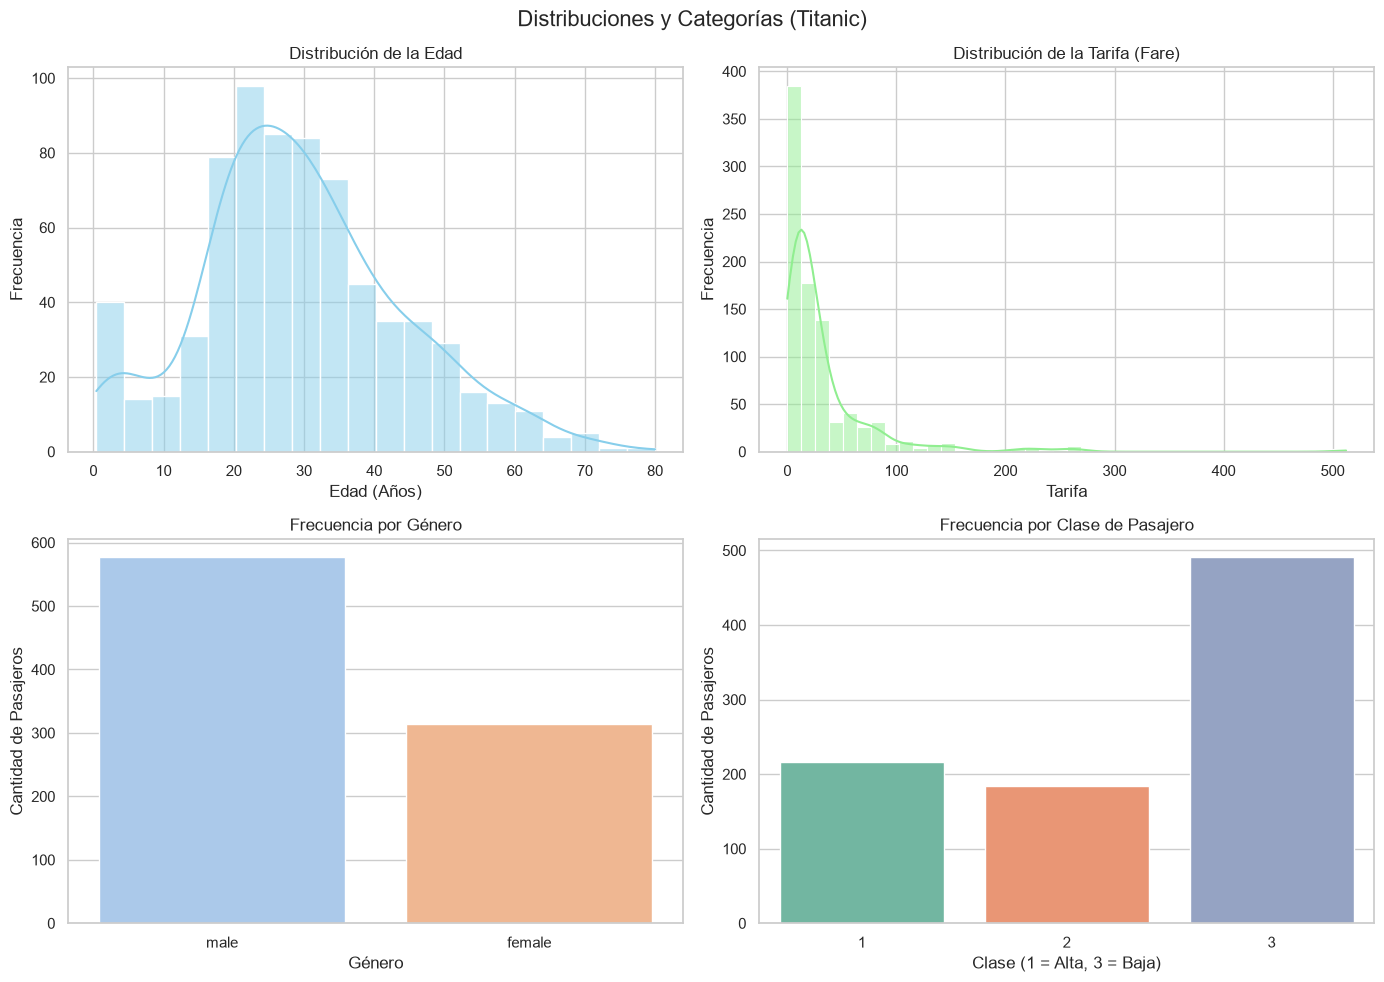

In [16]:
# Importar librerías gráficas 
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general
sns.set_theme(style="whitegrid")

# Crear una figura con 4 espacios (2x2)
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Distribuciones y Categorías (Titanic)', fontsize=16)

# 1. Edad
sns.histplot(df_titanic['Age'], kde=True, ax=ax[0,0], color='skyblue')
ax[0,0].set_title('Distribución de la Edad')
ax[0,0].set_xlabel('Edad (Años)')
ax[0,0].set_ylabel('Frecuencia')

# 2. Tarifa pagada (Fare)
sns.histplot(df_titanic['Fare'], bins=40, kde=True, ax=ax[0,1], color='lightgreen')
ax[0,1].set_title('Distribución de la Tarifa (Fare)')
ax[0,1].set_xlabel('Tarifa')
ax[0,1].set_ylabel('Frecuencia')

# 3. Género
sns.countplot(x='Sex', data=df_titanic, ax=ax[1,0], palette='pastel')
ax[1,0].set_title('Frecuencia por Género')
ax[1,0].set_xlabel('Género')
ax[1,0].set_ylabel('Cantidad de Pasajeros')

# 4. Clase del pasajero (Pclass)
sns.countplot(x='Pclass', data=df_titanic, ax=ax[1,1], palette='Set2')
ax[1,1].set_title('Frecuencia por Clase de Pasajero')
ax[1,1].set_xlabel('Clase (1 = Alta, 3 = Baja)')
ax[1,1].set_ylabel('Cantidad de Pasajeros')

plt.tight_layout()
plt.show()

### 3.2 Análisis Bivariado y Correlación
Análisis para detectar valores atípicos mediante Boxplots y observar la relación entre los atributos y la variable objetivo (Supervivencia).

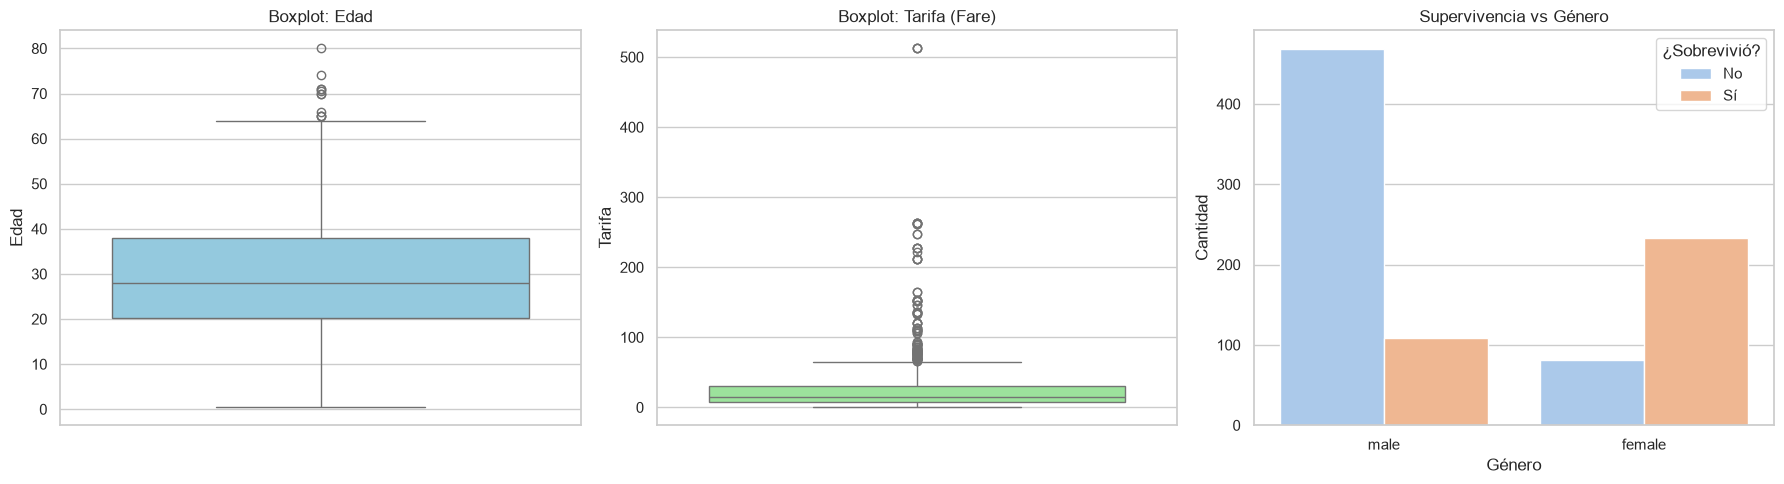

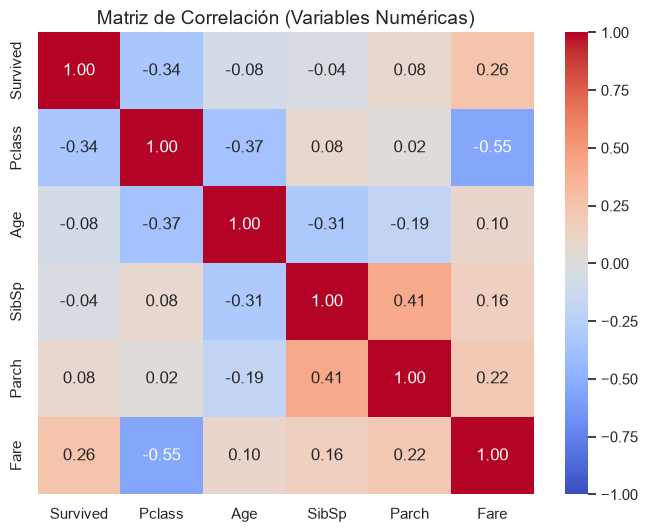

In [17]:
# Figura con 3 espacios para Boxplots y Relación Objetivo
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 1. Boxplot de la Edad
sns.boxplot(y='Age', data=df_titanic, ax=ax[0], color='skyblue')
ax[0].set_title('Boxplot: Edad')
ax[0].set_ylabel('Edad')

# 2. Boxplot de la Tarifa (Fare)
sns.boxplot(y='Fare', data=df_titanic, ax=ax[1], color='lightgreen')
ax[1].set_title('Boxplot: Tarifa (Fare)')
ax[1].set_ylabel('Tarifa')

# 3. Relación Atributo-Objetivo (Supervivencia vs Género)
sns.countplot(x='Sex', hue='Survived', data=df_titanic, ax=ax[2], palette='pastel')
ax[2].set_title('Supervivencia vs Género')
ax[2].set_xlabel('Género')
ax[2].set_ylabel('Cantidad')
ax[2].legend(title='¿Sobrevivió?', labels=['No', 'Sí'])

plt.tight_layout()
plt.show()

# 4. Matriz de Correlación
plt.figure(figsize=(8, 6))
# Seleccionar solo variables numéricas para la correlación
cols_numericas = df_titanic.select_dtypes(include=['float64', 'int64']).columns
# Calcular correlación (excluyendo el PassengerId)
matriz_corr = df_titanic[cols_numericas].drop('PassengerId', axis=1, errors='ignore').corr()

sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlación (Variables Numéricas)', fontsize=14)
plt.show()